# Atlas HardPos 16: épocas 0, 500 e 1000

Execute **apenas depois** de terminar o Run All de `navitran_vizz_reboot_gpt_squared_25_span.ipynb`. Este notebook espera os três `.pt` gerados pela **mesma execução**. A primeira célula de verificação interrompe a análise se faltar qualquer checkpoint.

Cada PS treinado é apresentado isoladamente ao modelo em `eval()`. As 208 ativações são extraídas em cada época e projetadas sobre **todas as posições** da malha 1001×1001 por meio do PS correspondente. A agregação espacial é 25×25, suavização gaussiana de 0,75 célula e anel de gridness 2,5–10 células. As escalas de cor de cada dimensão são fixas entre as três épocas e entre mapas brutos e suavizados. A saída inclui tabelas, matrizes, histogramas, pranchas PNG e um PDF.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

project_root = Path.cwd().resolve()
if not (project_root / 'navitran_vizz_reboot_gpt_squared_25_span.ipynb').is_file():
    raise FileNotFoundError('Abra este notebook com a raiz navitrans como diretório de trabalho.')
sys.path.insert(0, str(project_root / 'results' / 'hardpos_ps_gridness_exploration'))
import hardpos_atlas_three_epochs as atlas
print('Saída:', atlas.OUT)

Saída: /home/mgteus/workspace/navitrans/results/hardpos_atlas_evolucao/embed16_context10_epochs1000


## 1. Conferir os três checkpoints

A execução deve parar aqui se o treinamento ainda estiver em andamento ou se algum arquivo tiver outro nome.

In [2]:
checkpoints = atlas.check_inputs()
for epoch, path in checkpoints.items():
    print(f'Época {epoch:4d} | {path.name} | {path.stat().st_size:,} bytes')
print('Todos os insumos encontrados.')

Época    0 | gpt_model_HardPos_embed16_context10_epochs1000_epoch_0000.pt | 141,966 bytes
Época  500 | gpt_model_HardPos_embed16_context10_epochs1000_epoch_0500.pt | 141,966 bytes
Época 1000 | gpt_model_HardPos_embed16_context10_epochs1000_.pt | 141,638 bytes
Todos os insumos encontrados.


## 2. Arquitetura, PS e geometria

Usamos a definição da classe diretamente do notebook de treinamento e verificamos as formas dos pesos em cada arquivo.

In [3]:
model_class = atlas.load_model_class()
ps_ids = atlas.load_ps_ids()
geometry = atlas.load_geometry()
_, known_count, all_count, _ = geometry
print('PS treinados:', len(ps_ids))
print('Pontos conhecidos:', int(known_count.sum()), 'de', int(all_count.sum()))
print('Células pintadas:', int((known_count > 0).sum()), 'de', known_count.size)

PS treinados: 947
Pontos conhecidos: 1000055 de 1002001
Células pintadas: 625 de 625


## 3. Extrair as 208 ativações em cada época

Esta etapa lê os pesos salvos e executa os 947 PS individualmente. Não retoma nem altera o treinamento.

In [4]:
features_by_epoch = {}
feature_names = None
for epoch, path in checkpoints.items():
    names, features = atlas.extract_activations(path, model_class, ps_ids)
    if feature_names is None:
        feature_names = names
    elif names != feature_names:
        raise ValueError(f'As dimensões da época {epoch} diferem das anteriores.')
    features_by_epoch[epoch] = features
    print(f'Época {epoch}: matriz {features.shape}, checkpoint SHA-256 {atlas.sha256(path)[:16]}...')

Época 0: matriz (947, 208), checkpoint SHA-256 a813e9bd5386b67b...
Época 500: matriz (947, 208), checkpoint SHA-256 672fdb4934e0e18f...
Época 1000: matriz (947, 208), checkpoint SHA-256 42ae95e3388cbff1...


/home/mgteus/workspace/navitrans/.nav/lib/python3.10/site-packages/torch/nn/modules/transformer.py:307: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


## 4. Construir mapas e calcular G

Cada célula recebe a média de todos os pontos com PS conhecido. Não há imputação para os PS sem ativação treinada.

In [5]:
maps_by_epoch = {}
score_parts = []
for epoch, features in features_by_epoch.items():
    raw, smoothed = atlas.make_maps(features, geometry)
    maps_by_epoch[epoch] = (raw, smoothed)
    scores_epoch = atlas.save_stage(epoch, ps_ids, feature_names, features,
                                    raw, smoothed, geometry)
    score_parts.append(scores_epoch)
    print(f'Época {epoch}: {len(scores_epoch)} escores; máximo G suave = {scores_epoch.G_smoothed.max():+.3f}')
scores = pd.concat(score_parts, ignore_index=True)
scores.to_csv(atlas.OUT / 'gridness_tres_epocas.csv', index=False)
display(scores.groupby('epoch').agg(max_G=('G_smoothed','max'),
                                    positivos=('G_smoothed',lambda x:int((x>0).sum())),
                                    acima_de_0p5=('G_smoothed',lambda x:int((x>.5).sum()))))

Época 0: 208 escores; máximo G suave = +0.492
Época 500: 208 escores; máximo G suave = +0.493
Época 1000: 208 escores; máximo G suave = +0.338


,max_G,positivos,acima_de_0p5
epoch,,,
0,0.491677,32,0
500,0.493183,12,0
1000,0.338066,15,0


## 5. Gerar atlas e comparações

São 22 pranchas por época: 11 representações, cada uma nas versões bruta e suavizada. As figuras comparativas usam a mesma escala de cor por dimensão nos três momentos.

In [6]:
shared_ranges = atlas.plot_atlases(feature_names, maps_by_epoch, scores)
atlas.plot_comparisons(feature_names, maps_by_epoch, scores, shared_ranges)
print('Pranchas: 22 por época, 66 no total.')
print('Comparações:', atlas.OUT)

Pranchas: 22 por época, 66 no total.
Comparações: /home/mgteus/workspace/navitrans/results/hardpos_atlas_evolucao/embed16_context10_epochs1000


## 6. Controle por permutação conjunta de PS

Repetimos a mesma sequência de 100 permutações em cada época e comparamos o maior G entre as 208 dimensões. As permutações não alteram os atlas reais.

In [7]:
null_results = atlas.save_null_controls(features_by_epoch, scores, geometry,
                                        repeats=100, seed=20261013)
for epoch, result in null_results.items():
    print(f'Época {epoch}: G máximo {result["max_observed"]:+.3f}; '
          f'p empírico {result["empirical_p_max_208"]:.3f}')

Época 0: G máximo +0.492; p empírico 0.812
Época 500: G máximo +0.493; p empírico 0.832
Época 1000: G máximo +0.338; p empírico 1.000


## 7. Salvar o dossiê e visualizar as sínteses

Resumo: /home/mgteus/workspace/navitrans/results/hardpos_atlas_evolucao/embed16_context10_epochs1000/summary.json
PDF: /home/mgteus/workspace/navitrans/results/hardpos_atlas_evolucao/embed16_context10_epochs1000/atlas_tres_epocas.pdf
Páginas: 4 sínteses + 66 pranchas + 3 controles = 73


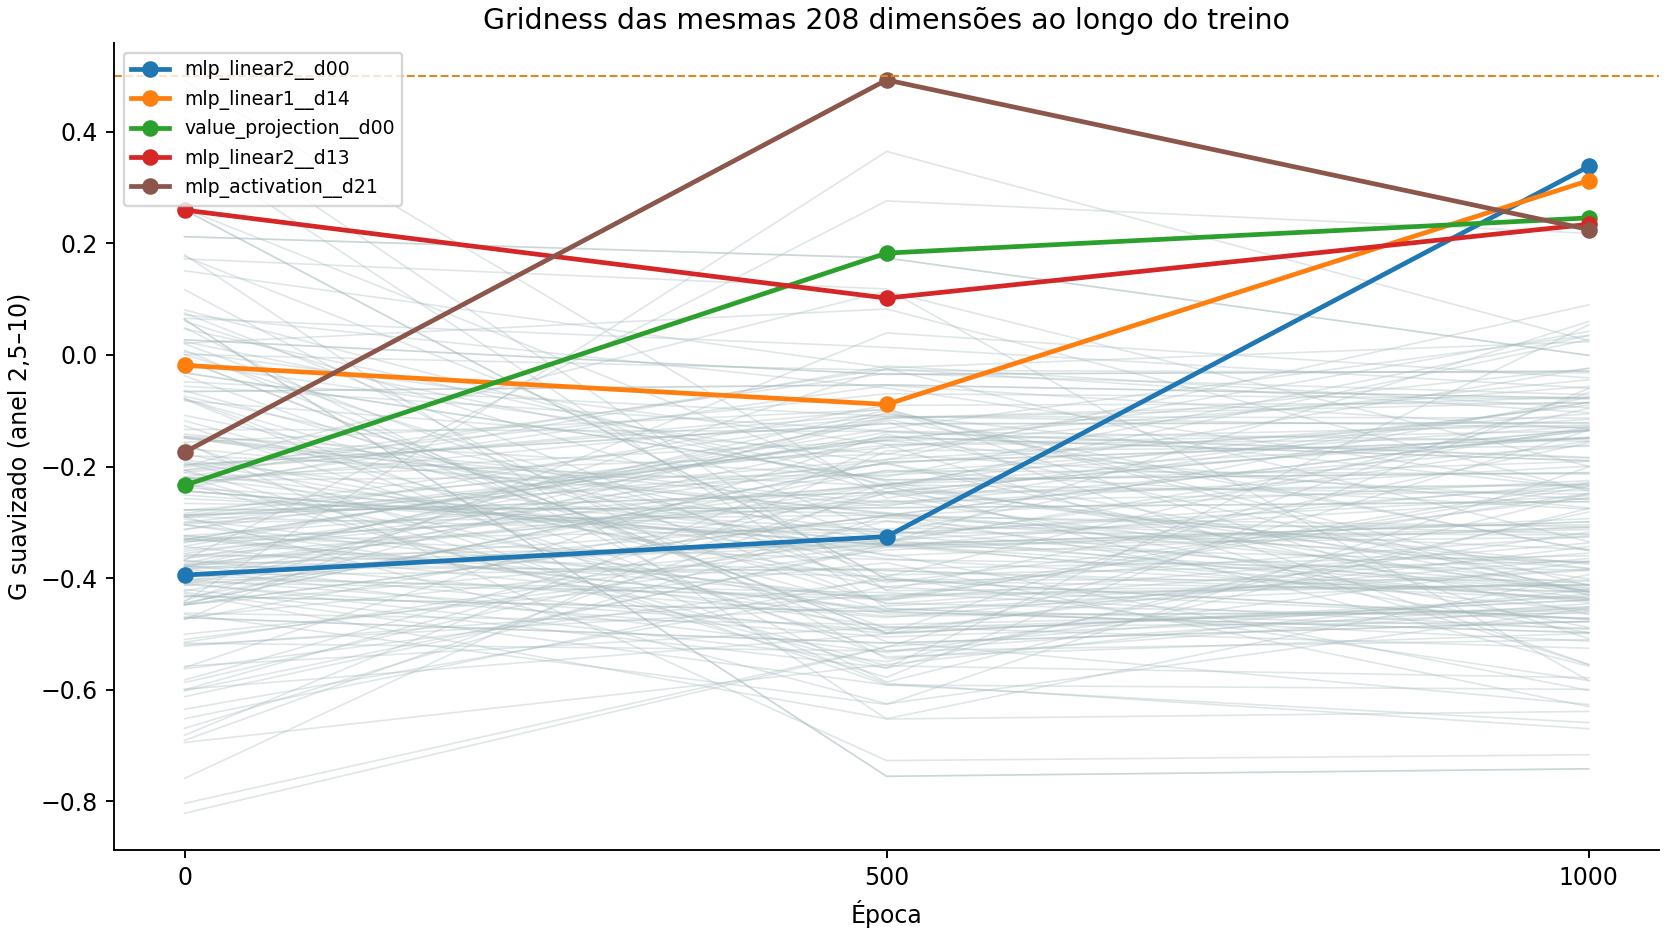

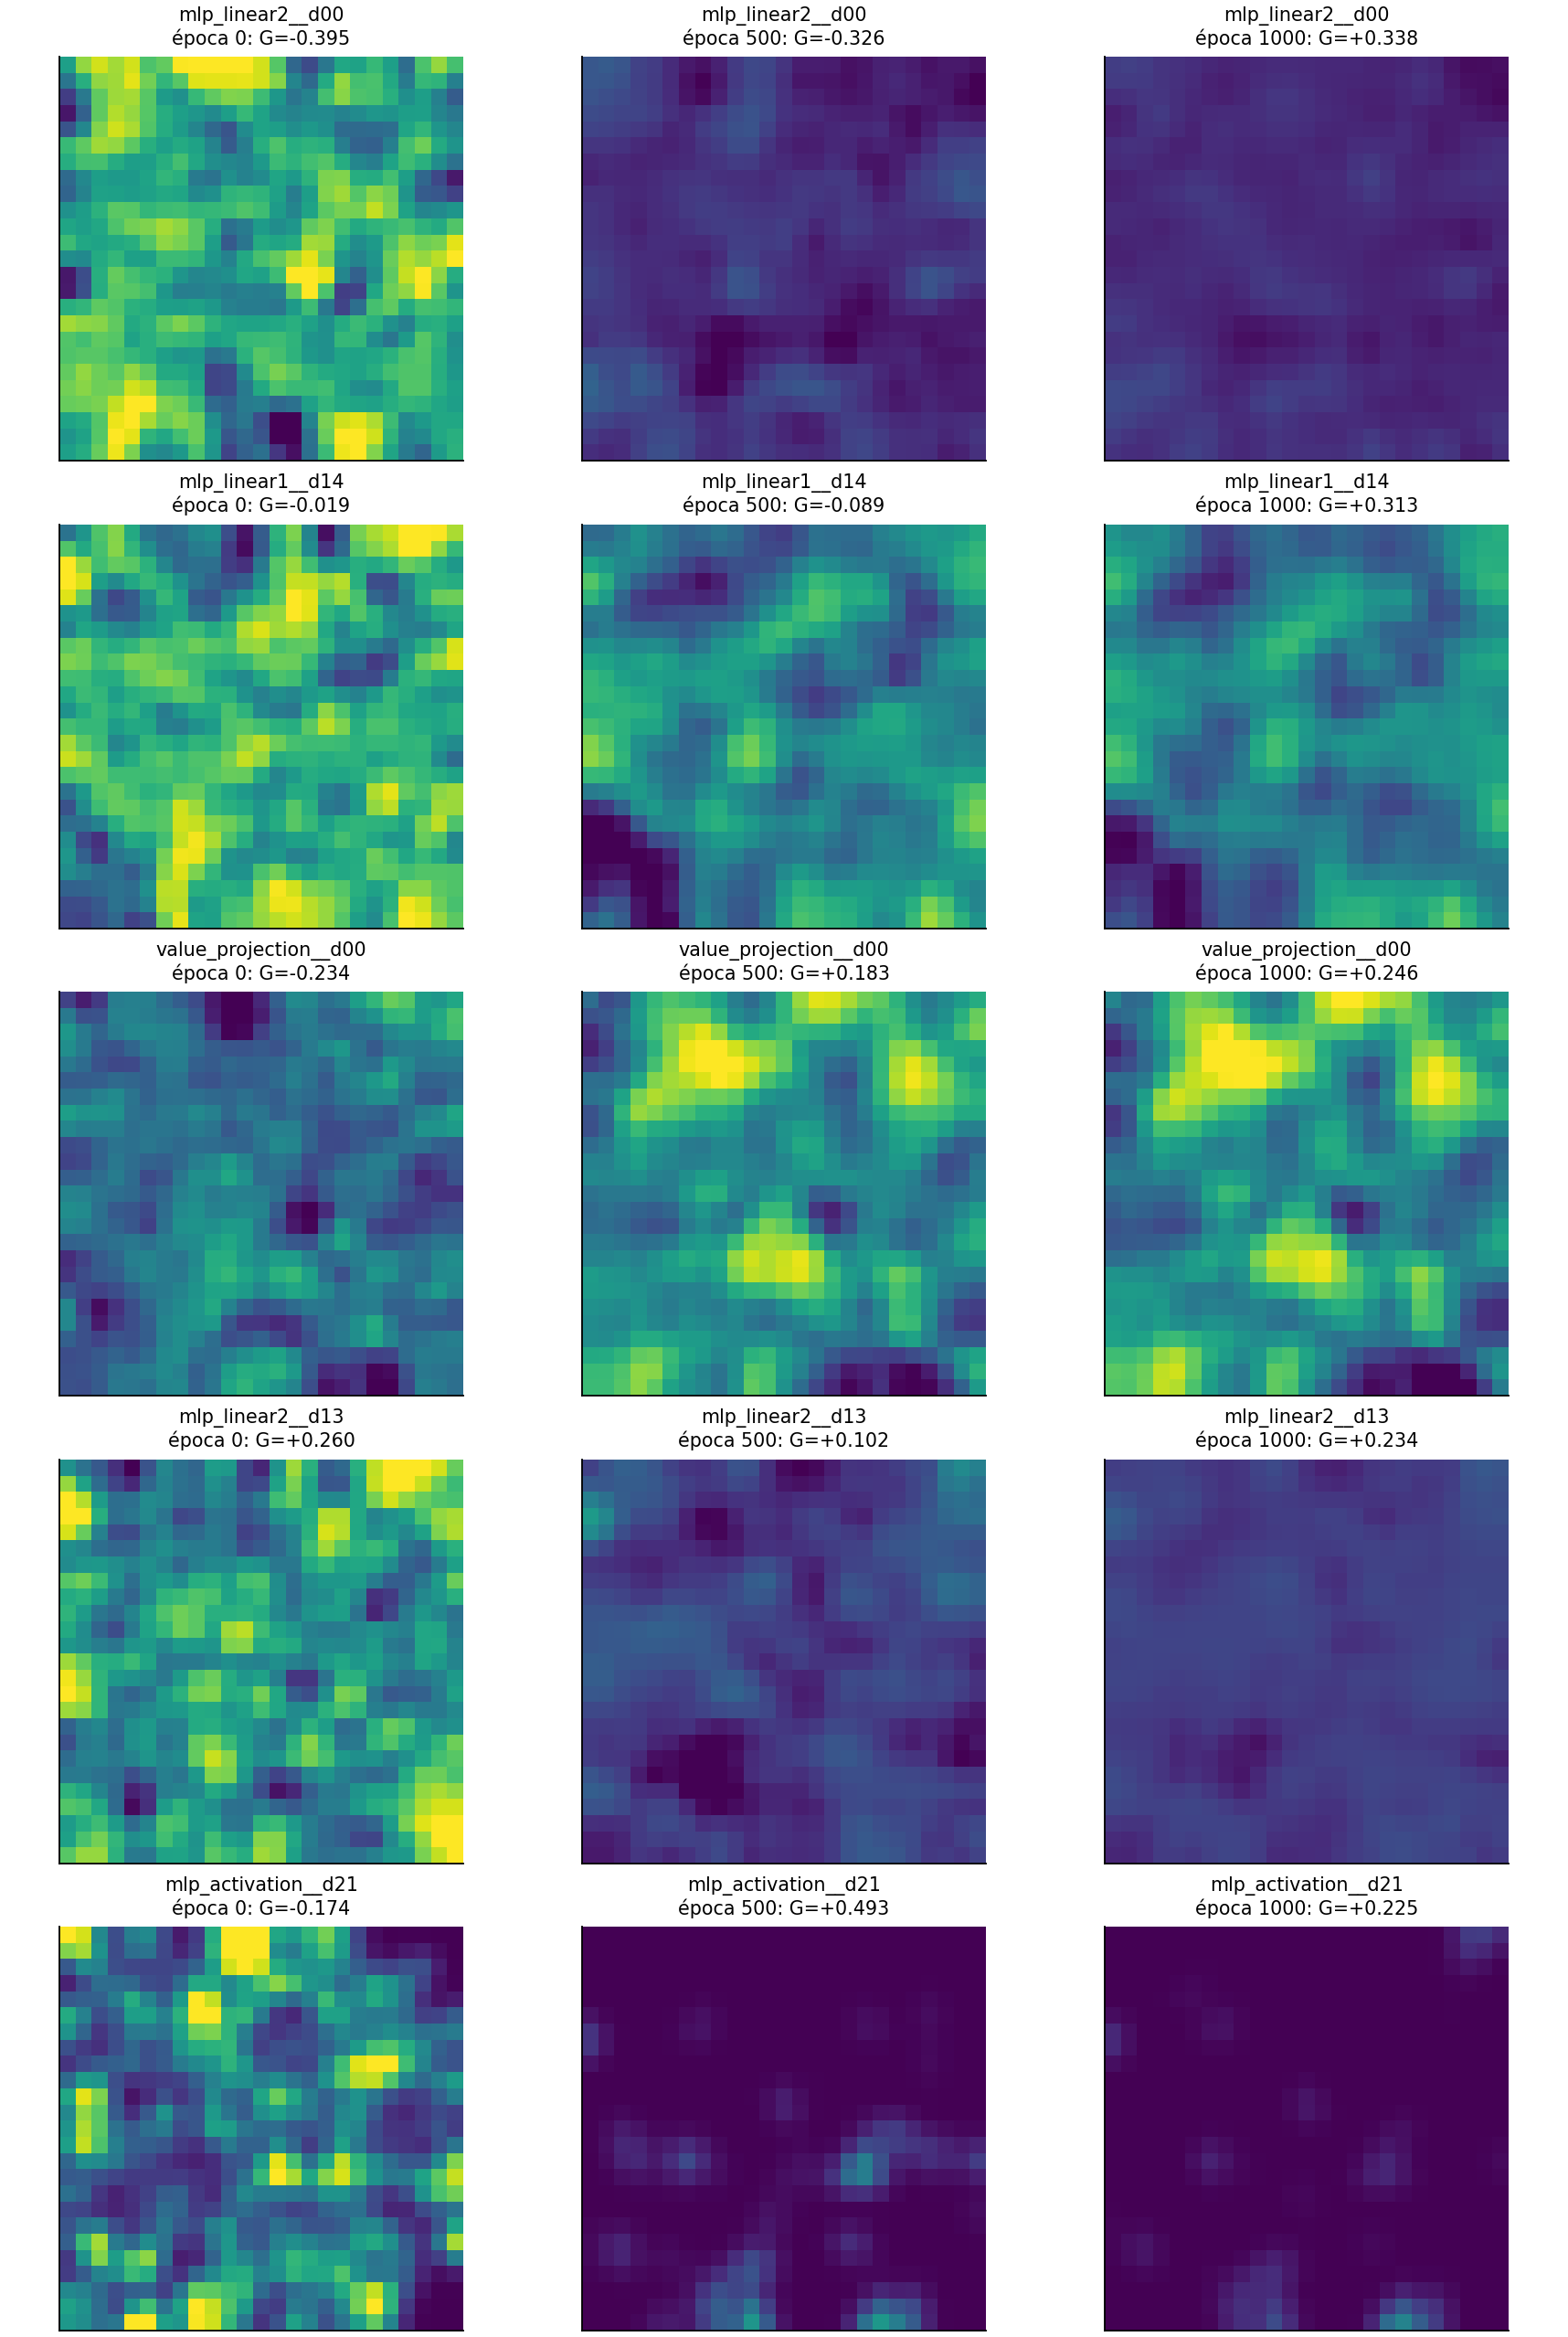

In [8]:
summary = atlas.save_summary(scores, geometry, null_results)
pdf_path = atlas.export_pdf()
print('Resumo:', atlas.OUT / 'summary.json')
print('PDF:', pdf_path)
print('Páginas: 4 sínteses + 66 pranchas + 3 controles = 73')
display(Image(filename=str(atlas.OUT / 'gridness_evolucao.png'), width=850))
display(Image(filename=str(atlas.OUT / 'top5_mapas_tres_epocas.png'), width=850))

## Leitura dos resultados

- O `G` e os mapas de uma dimensão devem ser comparados **pela mesma coluna de ativação** ao longo das épocas; as escalas visuais são fixas.
- Este protocolo usa **um PS por entrada**. O modelo foi treinado com contexto de até 10 PS, mas estes mapas não medem a dependência temporal desse histórico.
- O controle de permutação usa o máximo das 208 dimensões em cada repetição. Um G isolado acima de 0,5 não confirma um padrão hexagonal biológico.
- Saída: `results/hardpos_atlas_evolucao/embed16_context10_epochs1000/`. O PDF e os dados ficam nessa pasta; cada época possui seu subdiretório `epoch_0000`, `epoch_0500` ou `epoch_1000`.